In [85]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
import os
from sklearn.utils.class_weight import compute_sample_weight

In [86]:
df = pd.read_excel('C:/Users/hiteshree/Desktop/RBA/Trim 5/AML\Project/Phones classification.xlsx')
print(df.head())

   Sr No                             name  price (Rs)  rating (0-5)  RAM (GB)  \
0      1  APPLE iPhone 11 (Black, 128 GB)       45999           4.6         4   
1      2   APPLE iPhone 11 (Black, 64 GB)       38999           4.6         4   
2      3   APPLE iPhone 11 (Green, 64 GB)       42999           4.2         4   
3      4  APPLE iPhone 11 (Purple, 64 GB)       42999           4.6         4   
4      5    APPLE iPhone 11 (Red, 128 GB)       45999           4.6         4   

   ROM (GB)  Camera(mpx)  Display(cm)  Battery(mAh)  Benchmark score (AnTuTU)  \
0       128         12.0         15.4          3110                       628   
1        64         12.0         15.4          3110                       628   
2        64         12.0         15.4          3110                       628   
3        64         12.0         15.4          3110                       628   
4       128         12.0         15.4          3110                       628   

   Has 5G?  pred_class Bra

In [87]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Sr No                     699 non-null    int64  
 1   name                      699 non-null    object 
 2   price (Rs)                699 non-null    int64  
 3   rating (0-5)              699 non-null    float64
 4   RAM (GB)                  699 non-null    int64  
 5   ROM (GB)                  699 non-null    int64  
 6   Camera(mpx)               699 non-null    float64
 7   Display(cm)               699 non-null    float64
 8   Battery(mAh)              699 non-null    int64  
 9   Benchmark score (AnTuTU)  699 non-null    int64  
 10  Has 5G?                   699 non-null    int64  
 11  pred_class                699 non-null    int64  
 12  Brands                    699 non-null    object 
dtypes: float64(3), int64(8), object(2)
memory usage: 71.1+ KB


In [3]:
df.shape

(699, 13)

In [4]:
df = df.drop(df.columns[[0, 1, 2,9,12]], axis=1)
df.head()

,rating (0-5),RAM (GB),ROM (GB),Camera(mpx),Display(cm),Battery(mAh),Has 5G?,pred_class
0,4.6,4,128,12.0,15.4,3110,1,2
1,4.6,4,64,12.0,15.4,3110,1,2
2,4.2,4,64,12.0,15.4,3110,1,2
3,4.6,4,64,12.0,15.4,3110,1,2
4,4.6,4,128,12.0,15.4,3110,1,2


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   rating (0-5)  699 non-null    float64
 1   RAM (GB)      699 non-null    int64  
 2   ROM (GB)      699 non-null    int64  
 3   Camera(mpx)   699 non-null    float64
 4   Display(cm)   699 non-null    float64
 5   Battery(mAh)  699 non-null    int64  
 6   Has 5G?       699 non-null    int64  
 7   pred_class    699 non-null    int64  
dtypes: float64(3), int64(5)
memory usage: 43.8 KB


rating (0-5)       AxesSubplot(0.125,0.808774;0.227941x0.0712264)
RAM (GB)        AxesSubplot(0.398529,0.808774;0.227941x0.0712264)
ROM (GB)        AxesSubplot(0.672059,0.808774;0.227941x0.0712264)
Camera(mpx)        AxesSubplot(0.125,0.723302;0.227941x0.0712264)
Display(cm)     AxesSubplot(0.398529,0.723302;0.227941x0.0712264)
Battery(mAh)    AxesSubplot(0.672059,0.723302;0.227941x0.0712264)
Has 5G?             AxesSubplot(0.125,0.63783;0.227941x0.0712264)
pred_class       AxesSubplot(0.398529,0.63783;0.227941x0.0712264)
dtype: object

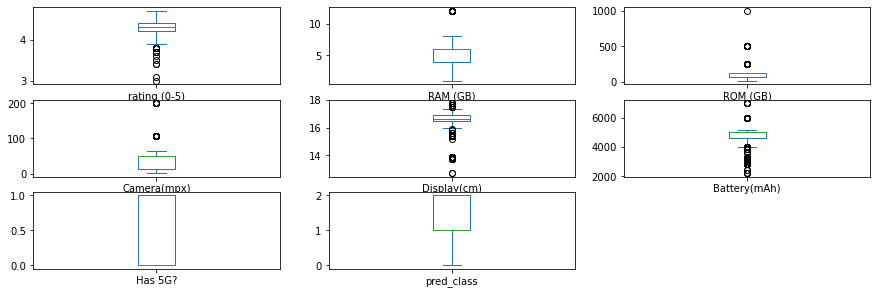

In [6]:
#BOX Plot

df.plot(kind = 'box',subplots = True, layout = (9,3), sharex = False, sharey = False, figsize = (15,15))

In [7]:
df['pred_class'].value_counts()

1    353
2    200
0    146
Name: pred_class, dtype: int64

In [8]:
df.corr()

,rating (0-5),RAM (GB),ROM (GB),Camera(mpx),Display(cm),Battery(mAh),Has 5G?,pred_class
rating (0-5),1.000000,0.075044,0.290160,-0.086371,-0.120469,-0.315938,0.282050,-0.205568
RAM (GB),0.075044,1.000000,0.516968,0.541231,0.173264,-0.025429,0.338045,-0.044072
ROM (GB),0.290160,0.516968,1.000000,0.208311,-0.094948,-0.294899,0.416507,-0.236124
Camera(mpx),-0.086371,0.541231,0.208311,1.000000,0.315271,0.261708,0.103918,0.318667
Display(cm),-0.120469,0.173264,-0.094948,0.315271,1.000000,0.657213,-0.238972,0.228797
Battery(mAh),-0.315938,-0.025429,-0.294899,0.261708,0.657213,1.000000,-0.424781,0.289455
Has 5G?,0.282050,0.338045,0.416507,0.103918,-0.238972,-0.424781,1.000000,-0.066425
pred_class,-0.205568,-0.044072,-0.236124,0.318667,0.228797,0.289455,-0.066425,1.000000


<AxesSubplot:>

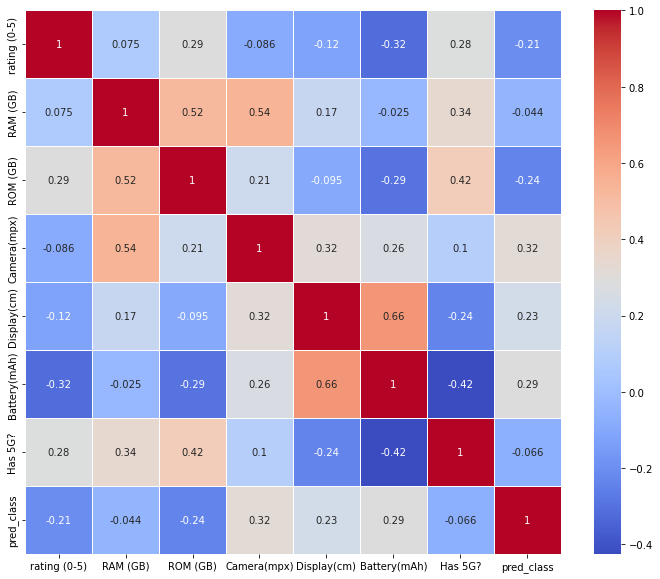

In [9]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", linecolor='white', linewidths=1)

In [10]:
Correlation_DF = df.corr()
Correlation_DF.head(9)

,rating (0-5),RAM (GB),ROM (GB),Camera(mpx),Display(cm),Battery(mAh),Has 5G?,pred_class
rating (0-5),1.000000,0.075044,0.290160,-0.086371,-0.120469,-0.315938,0.282050,-0.205568
RAM (GB),0.075044,1.000000,0.516968,0.541231,0.173264,-0.025429,0.338045,-0.044072
ROM (GB),0.290160,0.516968,1.000000,0.208311,-0.094948,-0.294899,0.416507,-0.236124
Camera(mpx),-0.086371,0.541231,0.208311,1.000000,0.315271,0.261708,0.103918,0.318667
Display(cm),-0.120469,0.173264,-0.094948,0.315271,1.000000,0.657213,-0.238972,0.228797
Battery(mAh),-0.315938,-0.025429,-0.294899,0.261708,0.657213,1.000000,-0.424781,0.289455
Has 5G?,0.282050,0.338045,0.416507,0.103918,-0.238972,-0.424781,1.000000,-0.066425
pred_class,-0.205568,-0.044072,-0.236124,0.318667,0.228797,0.289455,-0.066425,1.000000


In [11]:
df.dropna(inplace=True)
df.shape

(699, 8)

In [12]:
##Outlier Treatment

In [13]:
Columns_list = ["rating (0-5)","RAM (GB)","ROM (GB)","Camera(mpx)","Display(cm)","Battery(mAh)"]

In [14]:
for col in Columns_list:            
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3-q1 #Interquartile range
    low  = q1-1.5*iqr #acceptable range
    high = q3+1.5*iqr #acceptable range
    # Upper Limit
    df[col]=np.where(df[col] > high,high,df[col])
    # Lower Limit
    df[col]=np.where(df[col] < low,low,df[col]) 

rating (0-5)       AxesSubplot(0.125,0.808774;0.227941x0.0712264)
RAM (GB)        AxesSubplot(0.398529,0.808774;0.227941x0.0712264)
ROM (GB)        AxesSubplot(0.672059,0.808774;0.227941x0.0712264)
Camera(mpx)        AxesSubplot(0.125,0.723302;0.227941x0.0712264)
Display(cm)     AxesSubplot(0.398529,0.723302;0.227941x0.0712264)
Battery(mAh)    AxesSubplot(0.672059,0.723302;0.227941x0.0712264)
Has 5G?             AxesSubplot(0.125,0.63783;0.227941x0.0712264)
pred_class       AxesSubplot(0.398529,0.63783;0.227941x0.0712264)
dtype: object

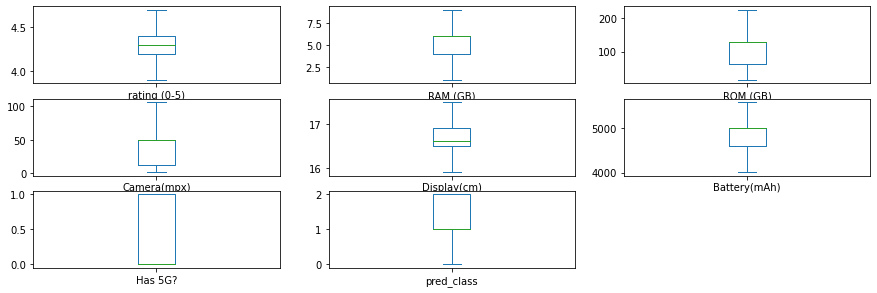

In [15]:
df.plot(kind = 'box',subplots = True, layout = (9,3), sharex = False, sharey = False, figsize = (15,15))

# Train test

In [16]:
X = df.drop(["pred_class"],axis=1)
Y = df["pred_class"]

In [17]:
x_train,x_test,y_train,y_test = train_test_split(X,Y,test_size=.3,random_state=40)

print("Train Data Size - ",x_train.shape[0],'\n')
print("Test Data Size - ",x_test.shape[0],'\n')

Train Data Size -  489 

Test Data Size -  210 



In [18]:
scaler = StandardScaler()
scaler.fit(x_train)
x_train = scaler.transform(x_train)
x_test = scaler.transform(x_test)

# Desicion Tree ID3


In [19]:
modCart = DecisionTreeClassifier(criterion="entropy")
param_grid = {"max_depth":np.arange(3,10)}
grids = GridSearchCV(modCart,param_grid)
grids.fit(x_train,y_train)
tree_preds = grids.predict_proba(x_test)[:,-1]

In [20]:
grids.best_params_

{'max_depth': 9}

In [21]:
grids.cv_results_

{'mean_fit_time': array([0.        , 0.00328817, 0.00396948, 0.00259852, 0.00081744,
        0.        , 0.0031251 ]),
 'std_fit_time': array([0.        , 0.00657635, 0.00600618, 0.00080001, 0.00100155,
        0.        , 0.00625019]),
 'mean_score_time': array([0.        , 0.        , 0.00039968, 0.00059962, 0.00019989,
        0.00312505, 0.        ]),
 'std_score_time': array([0.        , 0.        , 0.00048951, 0.00048959, 0.00039978,
        0.0062501 , 0.        ]),
 'param_max_depth': masked_array(data=[3, 4, 5, 6, 7, 8, 9],
              mask=[False, False, False, False, False, False, False],
        fill_value='?',
             dtype=object),
 'params': [{'max_depth': 3},
  {'max_depth': 4},
  {'max_depth': 5},
  {'max_depth': 6},
  {'max_depth': 7},
  {'max_depth': 8},
  {'max_depth': 9}],
 'split0_test_score': array([0.7755102 , 0.78571429, 0.80612245, 0.80612245, 0.80612245,
        0.85714286, 0.83673469]),
 'split1_test_score': array([0.78571429, 0.76530612, 0.80612245, 

In [22]:
modCART = DecisionTreeClassifier(max_depth=9,criterion="entropy")
modCART.fit(x_train,y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=9)

In [23]:
fn = X.columns

In [24]:
y_train_pred = modCART.predict(x_train)
print(confusion_matrix(y_train,y_train_pred))
print(classification_report(y_train,y_train_pred))
print("Accuracy is : ",accuracy_score(y_train,y_train_pred))
acc_dtid_train = accuracy_score(y_train,y_train_pred)
print (acc_dtid_train)

[[101   0   0]
 [  0 248  10]
 [  2  11 117]]
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       101
           1       0.96      0.96      0.96       258
           2       0.92      0.90      0.91       130

    accuracy                           0.95       489
   macro avg       0.95      0.95      0.95       489
weighted avg       0.95      0.95      0.95       489

Accuracy is :  0.9529652351738241
0.9529652351738241


In [25]:
y_test_pred1 = modCART.predict(x_test)
print(confusion_matrix(y_test,y_test_pred1))
print(classification_report(y_test,y_test_pred1))
print("Accuracy is : ",accuracy_score(y_test,y_test_pred1))
acc_dtid_test = accuracy_score (y_test,y_test_pred1)
print (acc_dtid_test)

[[43  0  2]
 [ 0 90  5]
 [ 5  6 59]]
              precision    recall  f1-score   support

           0       0.90      0.96      0.92        45
           1       0.94      0.95      0.94        95
           2       0.89      0.84      0.87        70

    accuracy                           0.91       210
   macro avg       0.91      0.92      0.91       210
weighted avg       0.91      0.91      0.91       210

Accuracy is :  0.9142857142857143
0.9142857142857143


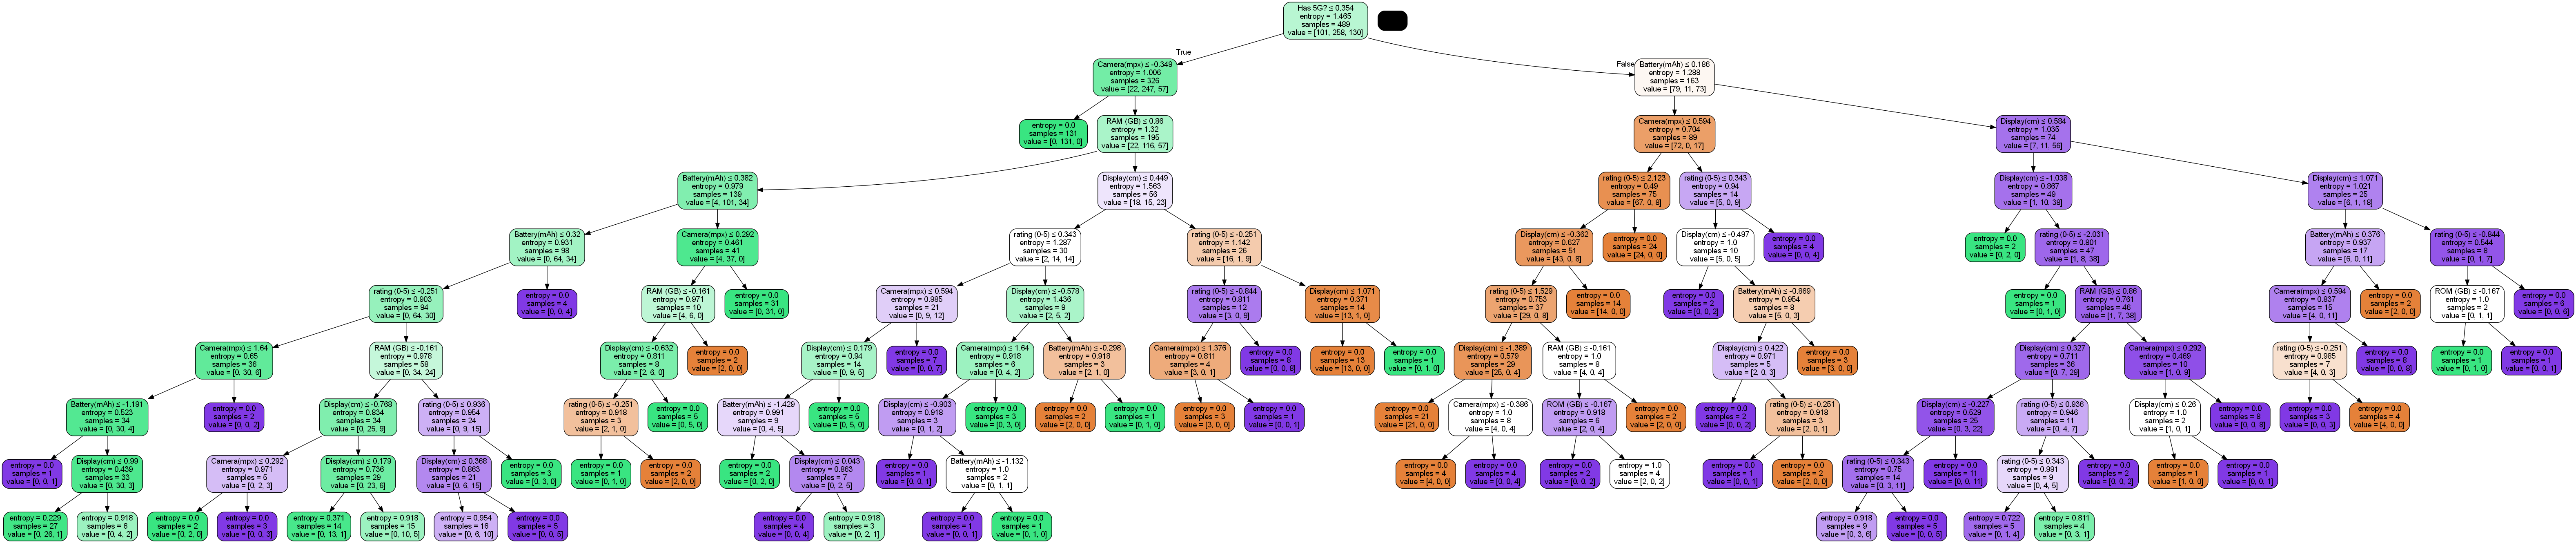

In [26]:
import graphviz
from six import StringIO
from  IPython.display import Image
from sklearn.tree import export_graphviz
import pydotplus
dot_data = StringIO()
export_graphviz(modCART,out_file=dot_data,filled=True,rounded=True,special_characters=True,feature_names = fn)
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
graphviz.Source(graph)
Image(graph.create_png())

# GINI Index

In [27]:
modCart = DecisionTreeClassifier(criterion="gini")
param_grid = {"max_depth":np.arange(3,10)}
grids = GridSearchCV(modCart,param_grid)
grids.fit(x_train,y_train)

GridSearchCV(estimator=DecisionTreeClassifier(),
             param_grid={'max_depth': array([3, 4, 5, 6, 7, 8, 9])})

In [28]:
grids.best_params_

{'max_depth': 8}

In [29]:
modCART = DecisionTreeClassifier(max_depth=8,criterion="gini")
modCART.fit(x_train,y_train)

DecisionTreeClassifier(max_depth=8)

In [30]:
y_train_pred = modCART.predict(x_train)
print(pd.crosstab(y_train,y_train_pred))
print(classification_report(y_train,y_train_pred))
print("Accuracy is : ",accuracy_score(y_train,y_train_pred))
acc_dtgini_train = accuracy_score (y_train,y_train_pred)
print (acc_dtgini_train)

col_0        0    1    2
pred_class              
0           98    0    3
1            0  245   13
2            2   12  116
              precision    recall  f1-score   support

           0       0.98      0.97      0.98       101
           1       0.95      0.95      0.95       258
           2       0.88      0.89      0.89       130

    accuracy                           0.94       489
   macro avg       0.94      0.94      0.94       489
weighted avg       0.94      0.94      0.94       489

Accuracy is :  0.9386503067484663
0.9386503067484663


In [31]:
y_test_pred = modCART.predict(x_test)
print(pd.crosstab(y_test,y_test_pred))
print(classification_report(y_test,y_test_pred))
print("Accuracy is : ",accuracy_score(y_test,y_test_pred))
acc_dtgini_test = accuracy_score (y_test,y_test_pred)
print (acc_dtgini_test)

col_0        0   1   2
pred_class            
0           38   0   7
1            0  90   5
2            7  10  53
              precision    recall  f1-score   support

           0       0.84      0.84      0.84        45
           1       0.90      0.95      0.92        95
           2       0.82      0.76      0.79        70

    accuracy                           0.86       210
   macro avg       0.85      0.85      0.85       210
weighted avg       0.86      0.86      0.86       210

Accuracy is :  0.861904761904762
0.861904761904762


In [32]:
fn = X.columns

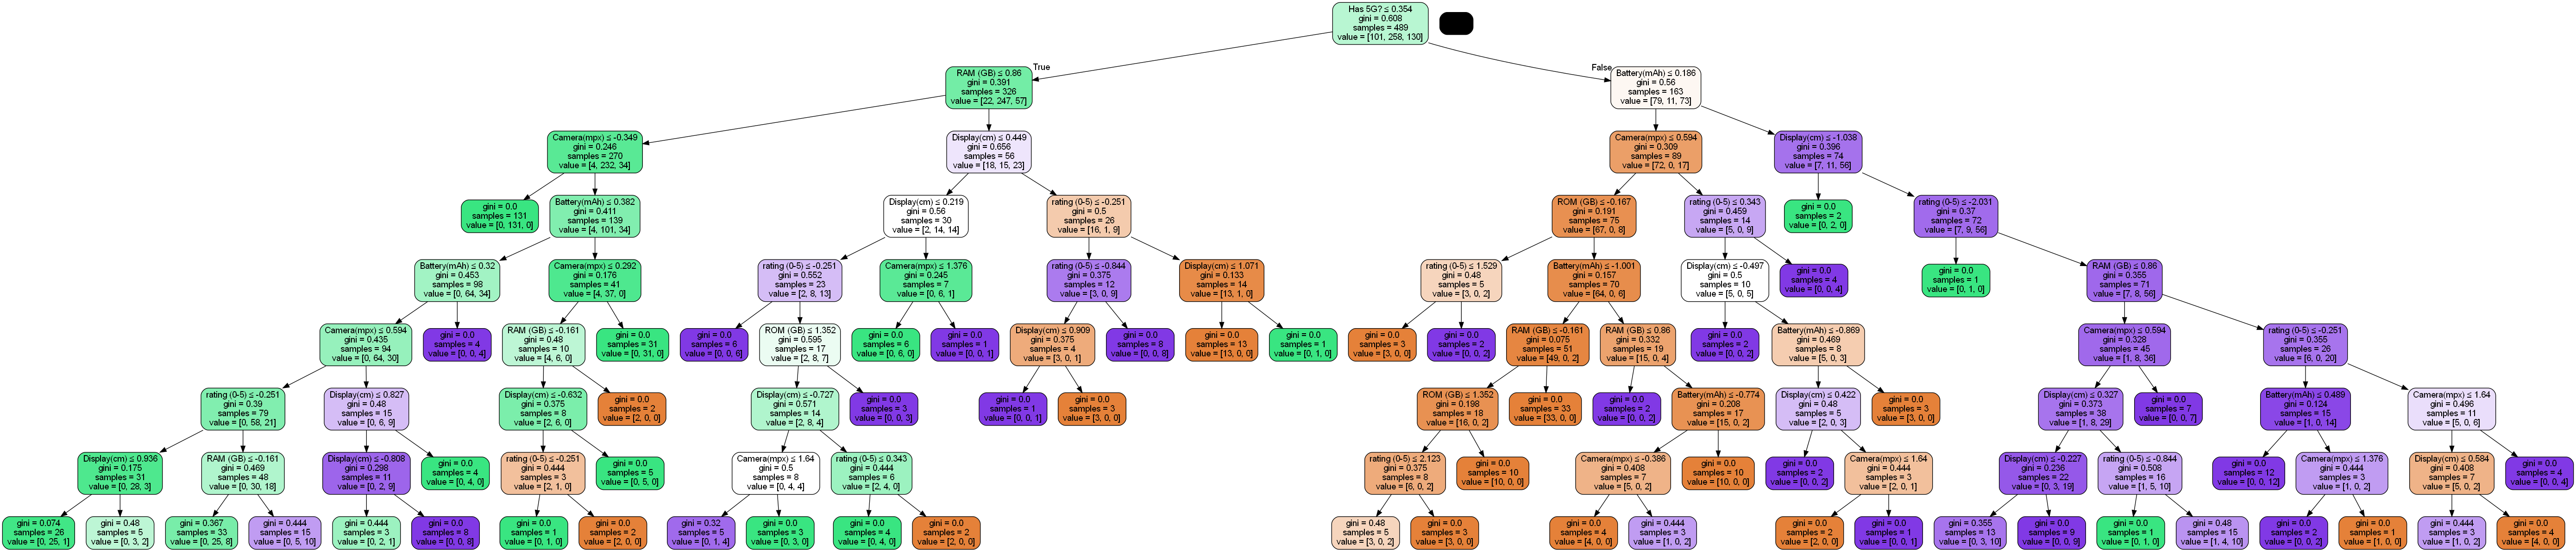

In [33]:
import graphviz
from six import StringIO
from  IPython.display import Image
from sklearn.tree import export_graphviz
import pydotplus
dot_data = StringIO()
export_graphviz(modCART,out_file=dot_data,filled=True,rounded=True,special_characters=True,feature_names = fn)
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
graphviz.Source(graph)
Image(graph.create_png())

# Random Forrest Entropy

In [82]:
rfc = RandomForestClassifier(n_estimators=15,criterion="entropy")
rfc.fit(x_train,y_train)

RandomForestClassifier(criterion='entropy', n_estimators=25)

In [83]:
y_train_pred2 = rfc.predict(x_train)
print(confusion_matrix(y_train,y_train_pred2))
print(classification_report(y_train,y_train_pred2))
print("Accuracy is : ",accuracy_score(y_train,y_train_pred2))
acc_dtgini_test = accuracy_score (y_test,y_test_pred)
print (acc_dtgini_test)

[[ 99   0   2]
 [  0 256   2]
 [  0   2 128]]
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       101
           1       0.99      0.99      0.99       258
           2       0.97      0.98      0.98       130

    accuracy                           0.99       489
   macro avg       0.99      0.99      0.99       489
weighted avg       0.99      0.99      0.99       489

Accuracy is :  0.9877300613496932
0.9877300613496932


In [84]:
y_test_pred2 = rfc.predict(x_test)
print(confusion_matrix(y_test,y_test_pred2))
print(classification_report(y_test,y_test_pred2))
print("Accuracy is : ",accuracy_score(y_test,y_test_pred2))
acc_rfent_test = accuracy_score (y_test,y_test_pred2)
print (acc_rfent_test)

[[40  0  5]
 [ 0 91  4]
 [ 5 11 54]]
              precision    recall  f1-score   support

           0       0.89      0.89      0.89        45
           1       0.89      0.96      0.92        95
           2       0.86      0.77      0.81        70

    accuracy                           0.88       210
   macro avg       0.88      0.87      0.87       210
weighted avg       0.88      0.88      0.88       210

Accuracy is :  0.8809523809523809
0.8809523809523809


# Random Forrest GINI

In [37]:
rfc = RandomForestClassifier(n_estimators=15,criterion="gini")
rfc.fit(x_train,y_train)

RandomForestClassifier(n_estimators=15)

In [38]:
y_train_pred2 = rfc.predict(x_train)
print(confusion_matrix(y_train,y_train_pred2))
print(classification_report(y_train,y_train_pred2))
print("Accuracy is : ",accuracy_score(y_train,y_train_pred2))
acc_rfgini_train = accuracy_score (y_train,y_train_pred2)
print (acc_rfgini_train)

[[ 99   0   2]
 [  0 254   4]
 [  0   1 129]]
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       101
           1       1.00      0.98      0.99       258
           2       0.96      0.99      0.97       130

    accuracy                           0.99       489
   macro avg       0.98      0.99      0.98       489
weighted avg       0.99      0.99      0.99       489

Accuracy is :  0.9856850715746421
0.9856850715746421


In [39]:
y_test_pred2 = rfc.predict(x_test)
print(confusion_matrix(y_test,y_test_pred2))
print(classification_report(y_test,y_test_pred2))
print("Accuracy is : ",accuracy_score(y_test,y_test_pred2))
acc_rfgini_test = accuracy_score (y_test,y_test_pred2)
print (acc_rfgini_test)

[[40  0  5]
 [ 1 89  5]
 [ 6 12 52]]
              precision    recall  f1-score   support

           0       0.85      0.89      0.87        45
           1       0.88      0.94      0.91        95
           2       0.84      0.74      0.79        70

    accuracy                           0.86       210
   macro avg       0.86      0.86      0.86       210
weighted avg       0.86      0.86      0.86       210

Accuracy is :  0.861904761904762
0.861904761904762


# Gaussian Naive Bayes

In [40]:
model = GaussianNB()
model.fit(x_train,y_train)

GaussianNB()

In [41]:
y_train_pred = model.predict(x_train)
print(confusion_matrix(y_train,y_train_pred))
print(classification_report(y_train,y_train_pred))
print("Accuracy is : ",accuracy_score(y_train,y_train_pred))
acc_gnb_train = accuracy_score (y_train,y_train_pred)
print (acc_gnb_train)

[[ 65   4  32]
 [  2 227  29]
 [ 14  25  91]]
              precision    recall  f1-score   support

           0       0.80      0.64      0.71       101
           1       0.89      0.88      0.88       258
           2       0.60      0.70      0.65       130

    accuracy                           0.78       489
   macro avg       0.76      0.74      0.75       489
weighted avg       0.79      0.78      0.79       489

Accuracy is :  0.7832310838445807
0.7832310838445807


In [42]:
y_test_pred = model.predict(x_test)
print(confusion_matrix(y_test,y_test_pred))
print(classification_report(y_test,y_test_pred))
print("Accuracy is : ",accuracy_score(y_test,y_test_pred))
acc_gnb_test = accuracy_score (y_test,y_test_pred)
print (acc_gnb_test)

[[29  0 16]
 [ 1 85  9]
 [10 12 48]]
              precision    recall  f1-score   support

           0       0.72      0.64      0.68        45
           1       0.88      0.89      0.89        95
           2       0.66      0.69      0.67        70

    accuracy                           0.77       210
   macro avg       0.75      0.74      0.75       210
weighted avg       0.77      0.77      0.77       210

Accuracy is :  0.7714285714285715
0.7714285714285715


# KNN

In [43]:
model = KNeighborsClassifier()
param_grid = {"n_neighbors":np.arange(3,10)}
grids = GridSearchCV(model,param_grid)
grids.fit(x_train,y_train)
knn_preds = grids.predict(x_test)
knn_performabce = accuracy_score(y_test,knn_preds)

print("KNN:accuracy - {}".format(knn_performabce))

KNN:accuracy - 0.861904761904762


In [44]:
grids.best_params_

{'n_neighbors': 5}

In [45]:
model = KNeighborsClassifier(n_neighbors = 5)
model.fit(x_train, y_train)

KNeighborsClassifier()

In [46]:
y_train_pred = model.predict(x_train)
print(confusion_matrix(y_train,y_train_pred))
print(classification_report(y_train,y_train_pred))
print("Accuracy is : ",accuracy_score(y_train,y_train_pred))
acc_knn_train = accuracy_score (y_train,y_train_pred)
print (acc_knn_train)

[[ 86   5  10]
 [  6 232  20]
 [  8  12 110]]
              precision    recall  f1-score   support

           0       0.86      0.85      0.86       101
           1       0.93      0.90      0.92       258
           2       0.79      0.85      0.81       130

    accuracy                           0.88       489
   macro avg       0.86      0.87      0.86       489
weighted avg       0.88      0.88      0.88       489

Accuracy is :  0.8752556237218814
0.8752556237218814


In [47]:
y_test_pred = model.predict(x_test)
print(confusion_matrix(y_test,y_test_pred))
print(classification_report(y_test,y_test_pred))
print("Accuracy is : ",accuracy_score(y_test,y_test_pred))
acc_knn_test = accuracy_score (y_test,y_test_pred)
print (acc_knn_test)

[[38  1  6]
 [ 1 88  6]
 [ 6  9 55]]
              precision    recall  f1-score   support

           0       0.84      0.84      0.84        45
           1       0.90      0.93      0.91        95
           2       0.82      0.79      0.80        70

    accuracy                           0.86       210
   macro avg       0.85      0.85      0.85       210
weighted avg       0.86      0.86      0.86       210

Accuracy is :  0.861904761904762
0.861904761904762


# SVM
1) Kernel = rbf

2) Kernel = Polynomial

In [48]:
# Building a Support Vector Machine on train data
svc_model = SVC(kernel='rbf', gamma=0.5, C=0.1)
svc_model.fit(x_train, y_train)

SVC(C=0.1, gamma=0.5)

In [49]:
y_train_pred = svc_model.predict(x_train)
print(confusion_matrix(y_train,y_train_pred))
print(classification_report(y_train,y_train_pred))
print("Accuracy is : ",accuracy_score(y_train,y_train_pred))
acc_svm_train = accuracy_score (y_train,y_train_pred)
print (acc_svm_train)

[[ 41  51   9]
 [  0 253   5]
 [  2  82  46]]
              precision    recall  f1-score   support

           0       0.95      0.41      0.57       101
           1       0.66      0.98      0.79       258
           2       0.77      0.35      0.48       130

    accuracy                           0.70       489
   macro avg       0.79      0.58      0.61       489
weighted avg       0.75      0.70      0.66       489

Accuracy is :  0.6952965235173824
0.6952965235173824


In [50]:
y_test_pred = svc_model.predict(x_test)
print(confusion_matrix(y_test,y_test_pred))
print(classification_report(y_test,y_test_pred))
print("Accuracy is : ",accuracy_score(y_test,y_test_pred))
acc_svm_test = accuracy_score (y_test,y_test_pred)
print (acc_svm_test)

[[13 28  4]
 [ 0 93  2]
 [ 1 49 20]]
              precision    recall  f1-score   support

           0       0.93      0.29      0.44        45
           1       0.55      0.98      0.70        95
           2       0.77      0.29      0.42        70

    accuracy                           0.60       210
   macro avg       0.75      0.52      0.52       210
weighted avg       0.70      0.60      0.55       210

Accuracy is :  0.6
0.6


In [51]:
# Building a Support Vector Machine on train data
svc_model = SVC(kernel='poly', degree=3, C=0.1)
svc_model.fit(x_train, y_train)

SVC(C=0.1, kernel='poly')

In [52]:
y_train_pred = svc_model.predict(x_train)
print(confusion_matrix(y_train,y_train_pred))
print(classification_report(y_train,y_train_pred))
print("Accuracy is : ",accuracy_score(y_train,y_train_pred))
acc_svmp_train = accuracy_score (y_train,y_train_pred)
print (acc_svmp_train)

[[ 64  21  16]
 [  0 257   1]
 [  5  85  40]]
              precision    recall  f1-score   support

           0       0.93      0.63      0.75       101
           1       0.71      1.00      0.83       258
           2       0.70      0.31      0.43       130

    accuracy                           0.74       489
   macro avg       0.78      0.65      0.67       489
weighted avg       0.75      0.74      0.71       489

Accuracy is :  0.7382413087934561
0.7382413087934561


In [53]:
y_test_pred = svc_model.predict(x_test)
print(confusion_matrix(y_test,y_test_pred))
print(classification_report(y_test,y_test_pred))
print("Accuracy is : ",accuracy_score(y_test,y_test_pred))
acc_svmp_test = accuracy_score (y_test,y_test_pred)
print (acc_svmp_test)

[[29 10  6]
 [ 0 95  0]
 [ 6 48 16]]
              precision    recall  f1-score   support

           0       0.83      0.64      0.73        45
           1       0.62      1.00      0.77        95
           2       0.73      0.23      0.35        70

    accuracy                           0.67       210
   macro avg       0.73      0.62      0.61       210
weighted avg       0.70      0.67      0.62       210

Accuracy is :  0.6666666666666666
0.6666666666666666


In [54]:
score = [acc_dtid_train,acc_dtid_test,acc_dtgini_train,acc_dtgini_test,
        acc_rfent_train,acc_rfent_test,acc_rfgini_train,acc_rfgini_test,
        acc_gnb_train,acc_gnb_test,acc_knn_train,acc_knn_test
        ,acc_svm_train,acc_svm_test,acc_svmp_train,acc_svmp_test]
print (score)


[0.9529652351738241, 0.9142857142857143, 0.9386503067484663, 0.861904761904762, 0.9815950920245399, 0.8904761904761904, 0.9856850715746421, 0.861904761904762, 0.7832310838445807, 0.7714285714285715, 0.8752556237218814, 0.861904761904762, 0.6952965235173824, 0.6, 0.7382413087934561, 0.6666666666666666]


In [79]:
df = pd.DataFrame(score, index =['acc_dtid_train','acc_dtid_test','acc_dtgini_train','acc_dtgini_test',
        'acc_rfent_train','acc_rfent_test','acc_rfgini_train','acc_rfgini_test',
        'acc_gnb_train','acc_gnb_test','acc_knn_train','acc_knn_test'
        ,'acc_svm_train','acc_svm_test','acc_svmp_train','acc_svmp_test'],
        columns =['Names'])
df

,Names
acc_dtid_train,0.952965
acc_dtid_test,0.914286
acc_dtgini_train,0.938650
acc_dtgini_test,0.861905
acc_rfent_train,0.981595
acc_rfent_test,0.890476
acc_rfgini_train,0.985685
acc_rfgini_test,0.861905
acc_gnb_train,0.783231
acc_gnb_test,0.771429


In [81]:
#df.to_excel("scores.xlsx", index = True)